# Kesit İstatistik — Dağılım ve yoğunluk araçları

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Hipergeometrik ve multinomial dağılımlar

Sonlu partiden yerine koymadan seçince hata olasılığı nedir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Hipergeometrik dağılımı aynı oranlı binom yaklaşımıyla karşılaştır.

**Yorum sınırı:** Multinomial sabit n ve toplamı 1 olan kategoriler içindir; bağımsız ayrı binomların toplamı sabit değildir.

**Alıştırma:** Örnekleme payını 10/100’den 60/100’e çıkar; sonlu evren farkını gör.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'hiper_P_en_az_1': np.float64(0.9738063082903304), 'multinomial_P_5_9_6': np.float64(0.03535537004999999)}


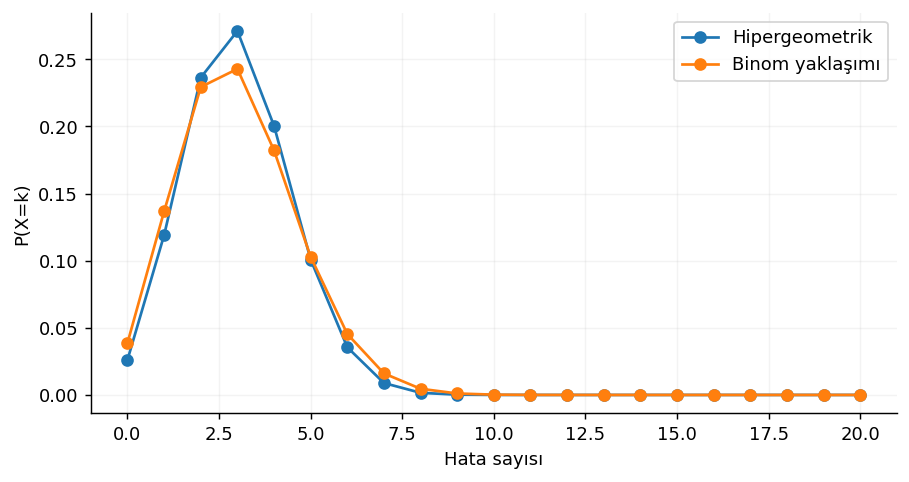

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

N,K,n=100,15,20;k=np.arange(n+1);hyper=stats.hypergeom(N,K,n).pmf(k);binom=stats.binom(n,K/N).pmf(k);counts=np.array([5,9,6]);p=np.array([.2,.5,.3]);print({'hiper_P_en_az_1':stats.hypergeom.sf(0,N,K,n),'multinomial_P_5_9_6':stats.multinomial.pmf(counts,n=20,p=p)})
assert np.isclose(hyper.sum(),1);plt.plot(k,hyper,'o-',label='Hipergeometrik');plt.plot(k,binom,'o-',label='Binom yaklaşımı');plt.xlabel('Hata sayısı');plt.ylabel('P(X=k)');plt.legend()

## Beta ve gamma aileleri

Gamma hız ve ölçek tanımlarını karıştırırsam ne olur?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı şekil için scale=1/rate ilişkisini açık tut.

**Yorum sınırı:** Beta 0–1 parametrelerini, gamma pozitif büyüklükleri modeller; tek bir şekil tüm veri için yeterli değildir.

**Alıştırma:** Gamma hızını 2’den 4’e çıkar; ortalama ve varyansın nasıl değiştiğini hesapla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'gamma_ortalama': np.float64(1.5), 'gamma_varyans': np.float64(0.75), 'gamma_P_X_2_alti': np.float64(0.7618966944464556), 'beta_ortalama': np.float64(0.2857142857142857)}


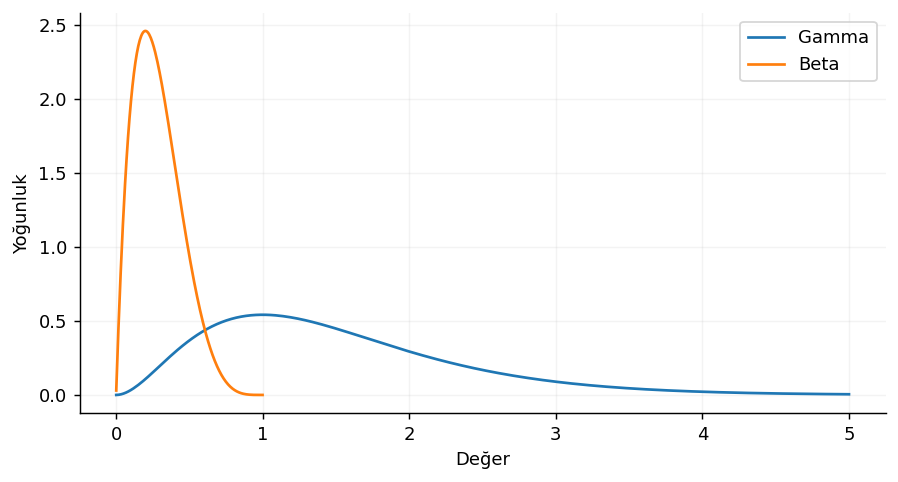

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

shape,rate=3.,2.;scale=1/rate;g=stats.gamma(a=shape,scale=scale);b=stats.beta(2,5);print({'gamma_ortalama':g.mean(),'gamma_varyans':g.var(),'gamma_P_X_2_alti':g.cdf(2),'beta_ortalama':b.mean()});x=np.linspace(.001,5,300);plt.plot(x,g.pdf(x),label='Gamma');xx=np.linspace(.001,.999,200);plt.plot(xx,b.pdf(xx),label='Beta');plt.xlabel('Değer');plt.ylabel('Yoğunluk');plt.legend()

## Weibull, hazard ve güvenilirlik

Henüz arızalanmamış birimi Weibull uyumuna nasıl dahil ederim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Sabit sansür zamanı altında yaşam eğrisiyle hazard biçimini ayır.

**Yorum sınırı:** Parametrik Weibull ve bağımsız sansür varsayılır; sansürü arıza saymak yanlıdır.

**Alıştırma:** Sansür zamanını 18’den 10’a indir; tahmin ve gözlenen olay sayısını karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'olay_n': 161, 'sansur_n': 139, 'uyum_sekil': np.float64(1.678654360886087), 'uyum_olcek': np.float64(21.12057042762909), 'gercek_sekil': 1.8, 'gercek_olcek': 20.0}


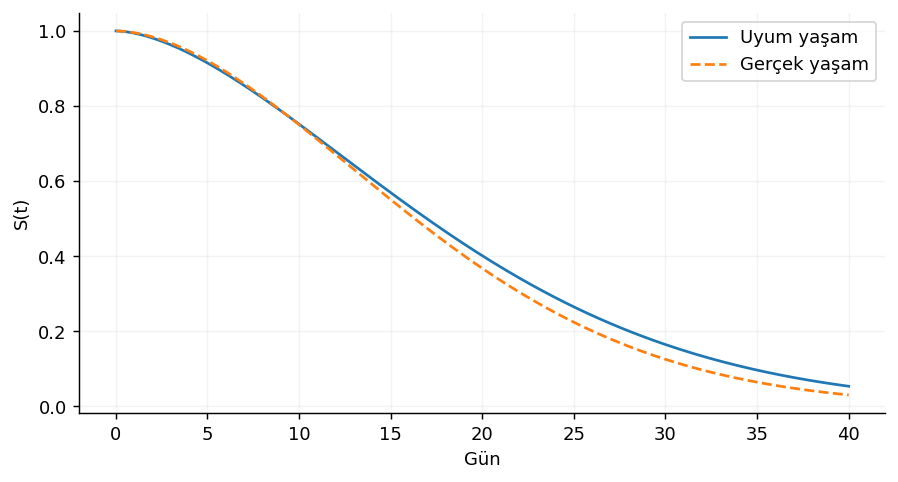

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

shape,scale=1.8,20.;life=stats.weibull_min.rvs(shape,scale=scale,size=300,random_state=rng);censor=18.;event=life<=censor;obs=np.minimum(life,censor);data=stats.CensoredData(uncensored=obs[event],right=obs[~event]);c,loc,s=stats.weibull_min.fit(data,floc=0);print({'olay_n':int(event.sum()),'sansur_n':int((~event).sum()),'uyum_sekil':c,'uyum_olcek':s,'gercek_sekil':shape,'gercek_olcek':scale})
x=np.linspace(.01,40,200);plt.plot(x,stats.weibull_min.sf(x,c,scale=s),label='Uyum yaşam');plt.plot(x,stats.weibull_min.sf(x,shape,scale=scale),'--',label='Gerçek yaşam');plt.xlabel('Gün');plt.ylabel('S(t)');plt.legend()

## Ampirik dağılım, ECDF ve yoğunluk tahmini

ECDF ile yoğunluk tahmini neden farklı çizilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** ECDF birikimli payı, KDE alanı 1 olan yoğunluğu gösterir.

**Yorum sınırı:** KDE bant genişliğine ve sınır yanlılığına duyarlıdır; negatif alana sızma pozitif süre modeliyle çelişebilir.

**Alıştırma:** bw_method=.2 yerine .6 yap; küçük tepelerin kaybolmasını yorumla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'n': 160, 'F_5': np.float64(0.8625), 'KDE_P_0_5': np.float64(0.8596896165316013), 'negatif_sizma': np.float64(0.001968165534576482)}


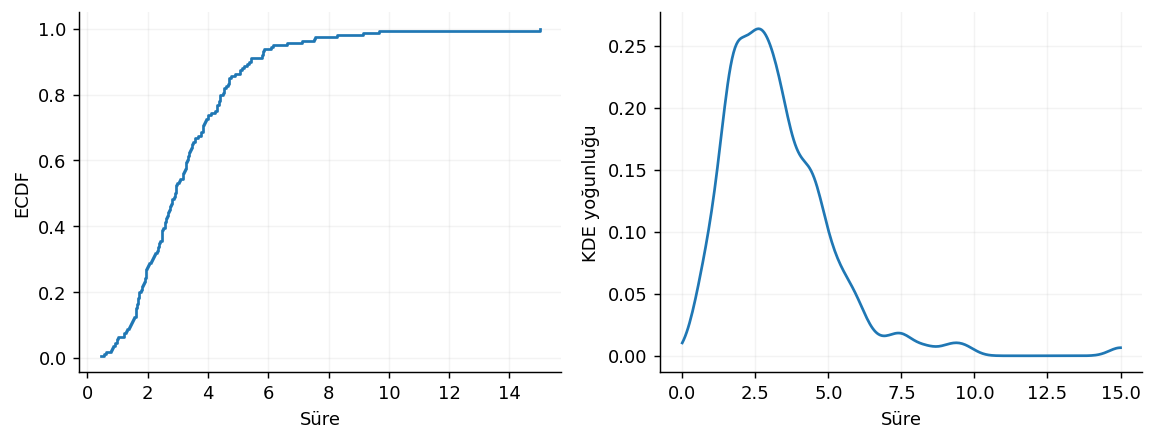

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.lognormal(1,.6,160);grid=np.linspace(0,15,300);kde=stats.gaussian_kde(x,bw_method=.2);sorted_x=np.sort(x);ecdf=np.arange(1,len(x)+1)/len(x);print({'n':len(x),'F_5':np.mean(x<=5),'KDE_P_0_5':kde.integrate_box_1d(0,5),'negatif_sizma':kde.integrate_box_1d(-np.inf,0)})
fig,axes=plt.subplots(1,2,figsize=(9,3.5));axes[0].step(sorted_x,ecdf,where='post');axes[0].set(xlabel='Süre',ylabel='ECDF');axes[1].plot(grid,kde(grid));axes[1].set(xlabel='Süre',ylabel='KDE yoğunluğu');fig.tight_layout()